# 🩺 Análise Multimodal de Áudio Clínico: Eventos Não-Verbais, Emoções na Voz e Discordância no Discurso

Este notebook implementa um pipeline completo para análise de consultas médicas em áudio (interação **Paciente–Médico**), combinando modelos locais de áudio e inteligência artificial generativa:

1. **Detecção de Sons Não-Verbais Medicamente Relevantes**: Identificação temporal de **tosse**, **espirro**, **limpeza de garganta (pigarro)**, **suspiro**, **gemido de dor** e **respiração ofegante** utilizando o modelo **Audio Spectrogram Transformer (AST)** pré-treinado no *AudioSet* (`MIT/ast-finetuned-audioset-10-10-0.4593`).
2. **Transcrição Segmentada com Whisper**: Uso do modelo local **OpenAI Whisper** para transcrever a consulta com *timestamps* precisos por segmento de fala.
3. **Reconhecimento Local de Emoções por Tom de Voz (SER)**: Classificação acústica das emoções em cada segmento de fala utilizando um modelo local baseado em **Wav2Vec2** (`ehcalabres/wav2vec2-lg-xlsr-en-speech-emotion-recognition`), complementado pela extração de métricas prosódicas via `librosa` (frequência fundamental $F_0$, energia RMS e variabilidade vocal).
4. **Análise Semântica e Comparação de Discordâncias via OpenAI API**: Uso do modelo da OpenAI (`gpt-4o-mini` / `gpt-4o`) para avaliar a emoção transmitida pelas palavras do discurso transcrito, identificar o interlocutor (*Paciente* ou *Médico*) e detectar **discordâncias (incongruências) emocionais** entre o que é dito verbalmente e o que o tom de voz revela.
5. **Relatório Clínico de Discordâncias e Linha do Tempo Multimodal**: Consolidação automática em relatório estruturado (`.md` e `.csv`) e visualizações gráficas.

## 1. Instalação e Importação de Bibliotecas
Descomente a célula abaixo caso precise instalar os pacotes no ambiente atual.

### Instalação de dependências para Diarização de Falantes
Para utilizar o `pyannote.audio`, precisamos instalar a biblioteca e suas dependências adicionais de processamento.

In [1]:
!pip install -q pyannote.audio

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


In [2]:
!pip install -q openai-whisper transformers torch torchaudio librosa soundfile openai pydantic pandas numpy matplotlib seaborn gTTS pydub python-dotenv

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pytorch-metric-learning 3.0.2 requires numpy>=2.5.3, but you have numpy 2.4.6 which is incompatible.


In [3]:
import json
import warnings
from pathlib import Path
from typing import Any, Literal

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import whisper
from dotenv import load_dotenv
from google.colab import userdata
from IPython.display import Audio, Markdown, display
from openai import OpenAI
from pydantic import BaseModel, Field
from transformers import pipeline

warnings.filterwarnings("ignore")
load_dotenv()

DEVICE = 0 if torch.cuda.is_available() else -1
TORCH_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo de execução selecionado: {TORCH_DEVICE.upper()}")

Dispositivo de execução selecionado: CUDA


## 2. Configuração da API da OpenAI e Parâmetros do Projeto
Defina sua chave `OPENAI_API_KEY` no arquivo `.env` ou diretamente na variável de ambiente abaixo.

In [4]:
# Caso não esteja usando arquivo .env, descomente e insira sua chave abaixo:
# os.environ["OPENAI_API_KEY"] = "sk-..."

OPENAI_MODEL = "gpt-4o-mini"  # Pode ser alterado para "gpt-4o"
WHISPER_MODEL_SIZE = "base"  # Opções: "tiny", "base", "small", "medium", "large"
SAMPLE_RATE = 16000
AUDIO_PATH = Path("/content/START_VIDEO_RECORDING_ky56r.wav")
try:
    api_key = userdata.get("OPENAI_API_KEY")
    client = OpenAI(api_key=api_key)
except Exception:
    print(
        "Chave 'OPENAI_API_KEY' não encontrada no Colab Secrets. Configure para usar a análise por LLM."
    )
    client = None

## 3. Obtenção ou Geração de Áudio Clínico de Exemplo
Se você já possui um arquivo de áudio de consulta médica (`.wav` ou `.mp3`), basta apontar o caminho em `AUDIO_PATH`.

Para permitir que este notebook seja executado imediatamente de ponta a ponta, a função abaixo gera automaticamente um áudio simulado de consulta clínica caso o arquivo não exista, intercalando:
- Falas entre **Médico** e **Paciente** (incluindo frases onde o paciente minimiza os sintomas verbalmente, como *"Está tudo ótimo doutor, não estou sentindo nada preocupante"*, para testar a análise de discordância emocional);
- Eventos acústicos não-verbais inseridos entre as falas (**tosse**, **limpeza de garganta/pigarro** e **espirro**).

In [7]:
def synthesize_non_verbal_sound(kind: str, sr: int = SAMPLE_RATE) -> np.ndarray:
    """Gera padrões acústicos sintéticos de eventos não-verbais para simulação caso não haja áudio externo."""
    rng = np.random.default_rng(42)
    if kind == "cough":
        # Tosse: 2 explosões curtas de energia de banda larga com decaimento exponencial
        dur = 0.75
        t = np.linspace(0, dur, int(sr * dur), endpoint=False)
        burst1 = np.exp(-(((t - 0.12) / 0.05) ** 2)) * (
            rng.normal(0, 0.6, len(t)) + 0.4 * np.sin(2 * np.pi * 220 * t)
        )
        burst2 = np.exp(-(((t - 0.42) / 0.06) ** 2)) * (
            rng.normal(0, 0.5, len(t)) + 0.35 * np.sin(2 * np.pi * 190 * t)
        )
        sig = burst1 + burst2
    elif kind == "throat_clearing":
        # Limpeza de garganta (pigarro): vibração gutural modulada (~110-160 Hz) + ruído fricativo
        dur = 0.9
        t = np.linspace(0, dur, int(sr * dur), endpoint=False)
        env = np.sin(np.pi * t / dur) ** 1.5
        carrier = 0.5 * np.sin(2 * np.pi * 130 * t + 4 * np.sin(2 * np.pi * 25 * t))
        noise = 0.35 * rng.normal(0, 1, len(t))
        sig = env * (carrier + noise)
    elif kind == "sneeze":
        # Espirro: inspiração rápida seguida de explosão de alta frequência
        dur = 0.8
        t = np.linspace(0, dur, int(sr * dur), endpoint=False)
        inhale = np.exp(-(((t - 0.18) / 0.07) ** 2)) * 0.25 * rng.normal(0, 1, len(t))
        outburst = np.exp(-(((t - 0.45) / 0.08) ** 2)) * 0.85 * rng.normal(0, 1, len(t))
        sig = inhale + outburst
    else:
        sig = np.zeros(int(sr * 0.5))
    max_val = np.max(np.abs(sig)) + 1e-8
    return (sig / max_val * 0.8).astype(np.float32)


def create_demo_clinical_audio(output_path: Path, sr: int = SAMPLE_RATE) -> Path:
    """Cria um áudio clínico demonstrativo com falas e sons não-verbais caso nenhum arquivo seja fornecido."""
    if output_path.exists():
        print(f"Arquivo de áudio encontrado em: {output_path}")
        return output_path

    print("Gerando áudio clínico demonstrativo para execução do pipeline...")
    segments_script = [
        ("speech", "Bom dia! Como você tem se sentido desde a última semana?"),
        ("event", "throat_clearing"),
        (
            "speech",
            "Ah doutor, está tudo ótimo comigo, não estou preocupado com nada e durmo super bem.",
        ),
        ("event", "cough"),
        (
            "speech",
            "Percebi que você tossiu agora. Essa tosse e o cansaço no peito continuam fortes à noite?",
        ),
        ("event", "sneeze"),
        (
            "speech",
            "Não é nada demais, é só um resfriado leve, estou muito tranquilo quanto a isso.",
        ),
        ("event", "cough"),
        (
            "speech",
            "Na verdade, às vezes sinto falta de ar de madrugada e fico com medo de piorar sozinho em casa.",
        ),
    ]

    audio_chunks = []
    pause = np.zeros(int(0.4 * sr), dtype=np.float32)

    for idx, (seg_type, content) in enumerate(segments_script):
        if seg_type == "event":
            chunk = synthesize_non_verbal_sound(content, sr=sr)
            audio_chunks.append(chunk)
            audio_chunks.append(pause)
        else:
            try:
                from gtts import gTTS

                tmp_mp3 = output_path.parent / f"_tmp_tts_{idx}.mp3"
                tts = gTTS(text=content, lang="en", slow=False)
                tts.save(str(tmp_mp3))
                wav_seg, _ = librosa.load(str(tmp_mp3), sr=sr, mono=True)
                tmp_mp3.unlink(missing_ok=True)
                # Simula alteração prosódica sutil nos trechos do paciente para enriquecer o teste acústico
                if idx in (2, 6, 8):
                    wav_seg = librosa.effects.pitch_shift(wav_seg, sr=sr, n_steps=-1.5)
                audio_chunks.append(wav_seg.astype(np.float32))
                audio_chunks.append(pause)
            except Exception as e:
                print(
                    f"Aviso: gTTS indisponível ({e}). Gerando segmento de voz sintético para o trecho {idx}."
                )
                t = np.linspace(0, 2.5, int(2.5 * sr), endpoint=False)
                synth_voice = (
                    0.3 * np.sin(2 * np.pi * 165 * t) * (1 + 0.3 * np.sin(2 * np.pi * 4 * t))
                ).astype(np.float32)
                audio_chunks.append(synth_voice)
                audio_chunks.append(pause)

    full_audio = np.concatenate(audio_chunks)
    sf.write(str(output_path), full_audio, sr)
    print(
        f"Áudio clínico de exemplo salvo em: {output_path} (Duração: {len(full_audio) / sr:.1f}s)"
    )
    return output_path


AUDIO_PATH = create_demo_clinical_audio(AUDIO_PATH)
display(Audio(str(AUDIO_PATH)))

Arquivo de áudio encontrado em: /content/START_VIDEO_RECORDING_ky56r.wav


## 4. Módulo 1: Reconhecimento de Sons Não-Verbais Medicamente Relevantes
Utilizamos o modelo **AST (Audio Spectrogram Transformer)** pré-treinado no *AudioSet* (`MIT/ast-finetuned-audioset-10-10-0.4593`) para varrer o áudio com janelas deslizantes e detectar eventos não-verbais relevantes para o contexto clínico:
- **Tosse** (`Cough`)
- **Limpeza de garganta / Pigarro** (`Throat clearing`)
- **Espirro** (`Sneeze`)
- **Suspiro / Ofego / Falta de ar** (`Sigh`, `Pant`, `Gasp`, `Wheeze`, `Breathing`)
- **Fungada / Coriza** (`Sniff`, `Snort`)
- **Choro / Gemido de dor** (`Crying, sobbing`, `Groan`, `Grunt`, `Whimper`)

In [ ]:
# Mapeamento de rótulos do AudioSet para categorias clínicas em Português
CLINICAL_SOUND_MAP: dict[str, str] = {
    "Cough": "Tosse",
    "Throat clearing": "Limpeza de Garganta (Pigarro)",
    "Sneeze": "Espirro",
    "Sniff": "Fungada / Coriza",
    "Sigh": "Suspiro",
    "Gasp": "Arquejo / Falta de Ar",
    "Pant": "Respiração Ofegante",
    "Wheeze": "Sibilo / Chiado Respiratório",
    "Groan": "Gemido de Dor/Desconforto",
    "Grunt": "Grunhido de Esforço/Dor",
    "Crying, sobbing": "Choro / Soluço",
    "Whimper": "Queixume / Choro Contido",
    "Snort": "Ronco / Obstrução Nasal",
}

print("Carregando modelo AST para detecção de eventos acústicos não-verbais...")
ast_classifier = pipeline(
    "audio-classification", model="MIT/ast-finetuned-audioset-10-10-0.4593", device=DEVICE
)

Carregando modelo AST para detecção de eventos acústicos não-verbais...


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

In [ ]:
def detect_clinical_non_verbal_sounds(
    audio_path: Path,
    window_sec: float = 1.2,
    hop_sec: float = 0.6,
    score_threshold: float = 0.12,
    rms_min_threshold: float = 0.015,
) -> pd.DataFrame:
    """
    Analisa o áudio em janelas deslizantes usando o modelo AST (AudioSet)
    combinado a descritores espectrais para identificar sons não-verbais clínicos.
    """
    y, sr = librosa.load(str(audio_path), sr=SAMPLE_RATE, mono=True)
    win_len = int(window_sec * sr)
    hop_len = int(hop_sec * sr)

    raw_detections = []

    for start_sample in range(0, max(1, len(y) - win_len + 1), hop_len):
        end_sample = min(len(y), start_sample + win_len)
        segment = y[start_sample:end_sample]
        start_t = round(start_sample / sr, 2)
        end_t = round(end_sample / sr, 2)

        rms = float(np.sqrt(np.mean(segment**2)))
        if rms < rms_min_threshold:
            continue

        preds = ast_classifier({"raw": segment, "sampling_rate": sr}, top_k=8)
        speech_score = sum(
            p["score"]
            for p in preds
            if p["label"] in ("Speech", "Conversation", "Narration, monologue")
        )

        for p in preds:
            label = p["label"]
            score = float(p["score"])
            if label in CLINICAL_SOUND_MAP and score >= score_threshold:
                raw_detections.append(
                    {
                        "inicio_s": start_t,
                        "fim_s": end_t,
                        "evento_en": label,
                        "evento_clinico": CLINICAL_SOUND_MAP[label],
                        "confianca": round(score, 3),
                        "energia_rms": round(rms, 4),
                        "prob_fala_simultanea": round(speech_score, 3),
                    }
                )
                break

    # Consolidação de janelas adjacentes do mesmo evento
    if not raw_detections:
        return pd.DataFrame(
            columns=["inicio_s", "fim_s", "evento_clinico", "evento_en", "confianca", "energia_rms"]
        )

    merged = [raw_detections[0]]
    for det in raw_detections[1:]:
        prev = merged[-1]
        if (
            det["evento_clinico"] == prev["evento_clinico"]
            and det["inicio_s"] <= prev["fim_s"] + 0.35
        ):
            prev["fim_s"] = max(prev["fim_s"], det["fim_s"])
            prev["confianca"] = round(max(prev["confianca"], det["confianca"]), 3)
            prev["energia_rms"] = round(max(prev["energia_rms"], det["energia_rms"]), 4)
        else:
            merged.append(det)

    return pd.DataFrame(merged)


df_non_verbal = detect_clinical_non_verbal_sounds(AUDIO_PATH)
print(f"Total de eventos não-verbais detectados: {len(df_non_verbal)}")
display(df_non_verbal)

Total de eventos não-verbais detectados: 2


,inicio_s,fim_s,evento_en,evento_clinico,confianca,energia_rms,prob_fala_simultanea
0,100.2,101.4,Sneeze,Espirro,0.189,0.0855,0.175
1,104.4,105.6,Sneeze,Espirro,0.313,0.0765,0.094


## 5. Módulo 2: Transcrição do Áudio com OpenAI Whisper (Local)
Utilizamos o modelo **OpenAI Whisper** localmente para realizar a transcrição completa do diálogo médico-paciente, preservando o tempo de início (`start`) e fim (`end`) de cada segmento falado.

In [ ]:
print(f"Carregando modelo Whisper ({WHISPER_MODEL_SIZE})...")
whisper_model = whisper.load_model(WHISPER_MODEL_SIZE, device=TORCH_DEVICE)


def transcribe_clinical_audio(audio_path: Path, language: str = "en") -> list[dict[str, Any]]:
    """Transcreve o áudio com Whisper retornando segmentos temporais detalhados."""
    result = whisper_model.transcribe(
        str(audio_path), language=language, verbose=False, fp16=torch.cuda.is_available()
    )
    segments = []
    for idx, seg in enumerate(result.get("segments", [])):
        text = seg.get("text", "").strip()
        if text:
            segments.append(
                {
                    "segment_id": idx + 1,
                    "inicio_s": round(float(seg["start"]), 2),
                    "fim_s": round(float(seg["end"]), 2),
                    "transcricao": text,
                }
            )
    return segments


transcribed_segments = transcribe_clinical_audio(AUDIO_PATH)
df_transcricao = pd.DataFrame(transcribed_segments)
display(df_transcricao)

Carregando modelo Whisper (base)...


100%|██████████| 41830/41830 [00:08<00:00, 5160.99frames/s]


,segment_id,inicio_s,fim_s,transcricao
0,1,0.0,27.0,"Hi, my name is Pepper. I am a robot doctor. He..."
1,2,27.0,34.0,My name is Anne Jones and my date of birth is ...
2,3,39.0,44.0,Thank you. May I ask which is back to you and ...
3,4,45.0,50.0,I've noticed a couple of symptoms about a mont...
4,5,50.0,55.0,"My hands have been shaking, I've been falling ..."
5,6,55.0,59.0,"People know that my walking has changed, I've ..."
6,7,59.0,63.0,"I've sometimes been painting, I've troubles sl..."
7,8,63.0,67.0,I've been trying throughout the day. I'm strug...
8,9,67.0,71.0,"Talks like it do. Pairs be like, can you just ..."
9,10,71.0,74.0,These are touching me.


## 5.1. Diarização e Identificação de Falantes com Pyannote

Nesta etapa, carregamos o pipeline de Diarização do Pyannote para identificar os turnos de fala dos dois participantes (*Doctor* e *Patient*). Para usar os modelos do Pyannote, é necessário aceitar os termos de uso no Hugging Face (modelos `pyannote/speaker-diarization-3.1` ou `pyannote/speaker-diarization`) e obter um Token de Acesso (HF_TOKEN) configurado no segredo do Colab.

In [ ]:
from pyannote.audio import Pipeline

print("Carregando o pipeline de diarização oficial pyannote/speaker-diarization-community-1...")
HF_TOKEN = userdata.get("HF_TOKEN")

# Carrega exatamente o pipeline solicitado pelo usuário
diarization_pipeline = Pipeline.from_pretrained(
    "pyannote/speaker-diarization-community-1", token=HF_TOKEN
)

if torch.cuda.is_available() and diarization_pipeline is not None:
    diarization_pipeline.to(torch.device("cuda"))

print("Pipeline pyannote/speaker-diarization-community-1 carregado com sucesso!")

config.yaml:   0%|          | 0.00/444 [00:00<?, ?B/s]

segmentation/pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 5.91MB            

segmentation/pytorch_model.bin: downloading bytes:           |  0.00B            

plda/xvec_transform.npz: reconstructing file:   0%|          |  0.00B /  134kB            

plda/xvec_transform.npz: downloading bytes:           |  0.00B            

plda/plda.npz: reconstructing file:   0%|          |  0.00B /  134kB            

plda/plda.npz: downloading bytes:           |  0.00B            

embedding/pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 26.6MB            

embedding/pytorch_model.bin: downloading bytes:           |  0.00B            

Pipeline de Diarização do Pyannote carregado com sucesso!


In [ ]:
def run_diarization(audio_path: Path) -> list[dict[str, Any]]:
    """
    Executa a diarização e retorna uma lista de intervalos de tempo com seus respectivos speakers.
    """
    if diarization_pipeline is not None:
        # Executa diarização oficial
        diarization = diarization_pipeline(str(audio_path), num_speakers=2)
        segments = []
        for turn, _, speaker in diarization.itertracks(yield_label=True):
            segments.append(
                {
                    "inicio_s": round(turn.start, 2),
                    "fim_s": round(turn.end, 2),
                    "speaker_raw": speaker,
                }
            )
        return segments
    else:
        # Fallback estruturado para simulação caso o token do HF não esteja presente
        # O áudio gerado de exemplo tem ~25 segundos com alternância
        print(
            "Usando simulação de Diarização baseada nos tempos conhecidos do script demonstrativo."
        )
        return [
            {"inicio_s": 0.0, "fim_s": 4.2, "speaker_raw": "SPEAKER_00"},  # Médico
            {"inicio_s": 4.6, "fim_s": 9.5, "speaker_raw": "SPEAKER_01"},  # Paciente
            {"inicio_s": 10.1, "fim_s": 15.0, "speaker_raw": "SPEAKER_00"},  # Médico
            {"inicio_s": 15.4, "fim_s": 20.2, "speaker_raw": "SPEAKER_01"},  # Paciente
            {"inicio_s": 20.6, "fim_s": 25.0, "speaker_raw": "SPEAKER_01"},  # Paciente
        ]

In [ ]:
# Executa a diarização acústica real no áudio completo usando o modelo community-1


def run_real_diarization(audio_path: Path) -> list[dict[str, Any]]:
    print(f"Processando áudio completo ({audio_path.name}) com Pyannote (Community-1)...")
    output = diarization_pipeline(str(audio_path))

    segments = []

    # Siga estritamente a especificação oficial do modelo 'speaker-diarization-community-1'
    for turn, speaker in output.speaker_diarization:
        segments.append(
            {"inicio_s": round(turn.start, 2), "fim_s": round(turn.end, 2), "speaker_raw": speaker}
        )

    return segments


# Executa a segmentação real no arquivo inteiro
diarized_turns = run_real_diarization(AUDIO_PATH)

# Exibe o resultado real obtido da análise de canais
df_diarizacao = pd.DataFrame(diarized_turns)
display(df_diarizacao)

Processando áudio completo (START_VIDEO_RECORDING_3r.wav) com Pyannote (Community-1)...


,inicio_s,fim_s,speaker_raw
0,17.23,26.31,SPEAKER_00
1,27.17,32.26,SPEAKER_01
2,39.03,39.86,SPEAKER_00
3,39.99,42.47,SPEAKER_00
4,44.97,45.54,SPEAKER_01
...,...,...,...
65,394.25,404.74,SPEAKER_00
66,407.02,407.88,SPEAKER_00
67,408.90,409.37,SPEAKER_01
68,414.30,415.07,SPEAKER_00


## 5.2. Filtrando Apenas os Segmentos do Paciente
Utilizando a regra de negócio estabelecida de que um dos interlocutores se identifica como o Médico/Robô Doutor (que inicia a conversa com perguntas no script de simulação), mapeamos quem é o **Paciente** e filtramos o pipeline para conter unicamente esses trechos no processamento acústico de sentimentos e discordância verbal.

In [ ]:
# Identificação acústica do Paciente baseada no cruzamento de tempos robusto entre Whisper e Pyannote


def get_patient_speaker_id_acoustically(
    diarized_segments: list[dict[str, Any]], transcription_segments: list[dict[str, Any]]
) -> str:
    """
    Localiza o falante que se apresenta como médico/robô e define o outro como Paciente,
    usando interseção temporal e análise de palavras-chave.
    """
    robot_speaker = None

    # Palavras-chave indicando o médico/robô
    keywords = ["doctor", "robot", "doutor", "bom dia", "sentido", "consulta"]

    for seg in transcription_segments:
        texto = seg["transcricao"].lower()
        if any(kw in texto for kw in keywords):
            seg_start = seg["inicio_s"]
            seg_end = seg["fim_s"]

            # Encontra qual speaker tem maior sobreposição temporal com este segmento
            best_speaker = None
            max_overlap = 0.0
            for turn in diarized_segments:
                # Calcula a sobreposição (interseção) de intervalos
                overlap_start = max(seg_start, turn["inicio_s"])
                overlap_end = min(seg_end, turn["fim_s"])
                overlap = max(0.0, overlap_end - overlap_start)

                if overlap > max_overlap:
                    max_overlap = overlap
                    best_speaker = turn["speaker_raw"]

            if best_speaker:
                robot_speaker = best_speaker
                break

    all_speakers = list(set(turn["speaker_raw"] for turn in diarized_segments))

    if robot_speaker and len(all_speakers) >= 2:
        patient_speaker = [sp for sp in all_speakers if sp != robot_speaker][0]
    else:
        # Caso não consiga diferenciar pelo texto, assumimos o speaker que mais fala ou o SPEAKER_01 como padrão
        speaker_counts = {}
        for turn in diarized_segments:
            dur = turn["fim_s"] - turn["inicio_s"]
            speaker_counts[turn["speaker_raw"]] = speaker_counts.get(turn["speaker_raw"], 0.0) + dur

        # Paciente costuma falar menos ou ser o segundo speaker ativo
        sorted_speakers = sorted(speaker_counts.items(), key=lambda x: x[1])
        if sorted_speakers:
            patient_speaker = sorted_speakers[0][0]
        else:
            patient_speaker = "SPEAKER_01"

    print(
        f"Speaker do Robô/Médico: {robot_speaker} | Speaker do Paciente mapeado: {patient_speaker}"
    )
    return patient_speaker


# Recarrega a transcrição original antes de aplicar o filtro para evitar dataframe vazio
transcribed_segments = transcribe_clinical_audio(AUDIO_PATH)

# Obtém o ID correto do paciente
patient_speaker_id = get_patient_speaker_id_acoustically(diarized_turns, transcribed_segments)

# Filtra os segmentos de transcrição usando sobreposição de tempo máxima
patient_segments = []
for seg in transcribed_segments:
    seg_start = seg["inicio_s"]
    seg_end = seg["fim_s"]

    best_speaker = None
    max_overlap = 0.0

    for turn in diarized_turns:
        overlap_start = max(seg_start, turn["inicio_s"])
        overlap_end = min(seg_end, turn["fim_s"])
        overlap = max(0.0, overlap_end - overlap_start)

        if overlap > max_overlap:
            max_overlap = overlap
            best_speaker = turn["speaker_raw"]

    if best_speaker == patient_speaker_id:
        patient_segments.append(seg)

print(
    f"Segmentos de transcrição totais: {len(transcribed_segments)} | Segmentos acústicos do Paciente recuperados: {len(patient_segments)}"
)
transcribed_segments = patient_segments
df_transcricao = pd.DataFrame(transcribed_segments)
display(df_transcricao)

100%|██████████| 41830/41830 [00:08<00:00, 5115.55frames/s]

Speaker do Robô/Médico: SPEAKER_00 | Speaker do Paciente mapeado: SPEAKER_01
Segmentos de transcrição totais: 50 | Segmentos acústicos do Paciente recuperados: 25


,segment_id,inicio_s,fim_s,transcricao
0,2,27.0,34.0,My name is Anne Jones and my date of birth is ...
1,4,45.0,50.0,I've noticed a couple of symptoms about a mont...
2,5,50.0,55.0,"My hands have been shaking, I've been falling ..."
3,6,55.0,59.0,"People know that my walking has changed, I've ..."
4,7,59.0,63.0,"I've sometimes been painting, I've troubles sl..."
5,8,63.0,67.0,I've been trying throughout the day. I'm strug...
6,9,67.0,71.0,"Talks like it do. Pairs be like, can you just ..."
7,10,71.0,74.0,These are touching me.
8,12,91.0,96.0,What? Can you hear me the question?
9,14,109.0,112.0,No.


## 6. Módulo 3: Reconhecimento Local de Emoções por Tom de Voz (SER)
Para cada segmento de fala transcrito pelo Whisper, recortamos o trecho correspondente do áudio original e aplicamos:
1. **Modelo Local de Speech Emotion Recognition (SER)**: `ehcalabres/wav2vec2-lg-xlsr-en-speech-emotion-recognition` (arquitetura Wav2Vec2 XLSR ajustada para reconhecimento de emoções vocais como *tristeza, medo/ansiedade, raiva, calma, felicidade, desgosto, surpresa e neutro*).
2. **Extração de Características Prosódicas (`librosa`)**: Frequência fundamental média ($F_0$ / Pitch), desvio padrão do Pitch (instabilidade/tremor vocal), energia RMS e taxa de cruzamento por zero (ZCR), que auxiliam na interpretação acústica da emoção.

In [ ]:
SER_MODEL_NAME = "ehcalabres/wav2vec2-lg-xlsr-en-speech-emotion-recognition"

EMOTION_TRANSLATION_MAP: dict[str, str] = {
    "angry": "Raiva / Irritação",
    "calm": "Calma",
    "disgust": "Desconforto / Aversão",
    "fearful": "Medo / Ansiedade",
    "happy": "Alegria / Entusiasmo",
    "neutral": "Neutro",
    "sad": "Tristeza / Abatimento",
    "surprised": "Surpresa / Espanto",
    # Compatibilidade caso outro modelo Wav2Vec2 (ex: superb-er) seja usado
    "ang": "Raiva / Irritação",
    "hap": "Alegria / Entusiasmo",
    "neu": "Neutro",
    "sad": "Tristeza / Abatimento",
}

print(f"Carregando modelo local de emoções por tom de voz: {SER_MODEL_NAME}...")
ser_pipeline = pipeline("audio-classification", model=SER_MODEL_NAME, device=DEVICE)

Carregando modelo local de emoções por tom de voz: ehcalabres/wav2vec2-lg-xlsr-en-speech-emotion-recognition...


config.json:   0%|          | 0.00/2.28k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.27GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForSequenceClassification LOAD REPORT from: ehcalabres/wav2vec2-lg-xlsr-en-speech-emotion-recognition
Key                      | Status     | 
-------------------------+------------+-
classifier.dense.bias    | UNEXPECTED | 
classifier.output.weight | UNEXPECTED | 
classifier.output.bias   | UNEXPECTED | 
classifier.dense.weight  | UNEXPECTED | 
projector.weight         | MISSING    | 
projector.bias           | MISSING    | 
classifier.bias          | MISSING    | 
classifier.weight        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


preprocessor_config.json:   0%|          | 0.00/214 [00:00<?, ?B/s]

In [ ]:
def extract_prosodic_features(segment_audio: np.ndarray, sr: int = SAMPLE_RATE) -> dict[str, float]:
    """Extrai métricas prosódicas (Pitch F0, variação de Pitch e Energia RMS) de um trecho de voz."""
    if len(segment_audio) < int(0.15 * sr):
        return {"pitch_medio_hz": 0.0, "pitch_std_hz": 0.0, "energia_rms": 0.0}

    rms = float(np.sqrt(np.mean(segment_audio**2)))
    f0, voiced_flag, _ = librosa.pyin(
        segment_audio, fmin=librosa.note_to_hz("C2"), fmax=librosa.note_to_hz("C6"), sr=sr
    )
    valid_f0 = f0[~np.isnan(f0)] if f0 is not None else np.array([])
    pitch_mean = float(np.mean(valid_f0)) if len(valid_f0) > 0 else 0.0
    pitch_std = float(np.std(valid_f0)) if len(valid_f0) > 0 else 0.0

    return {
        "pitch_medio_hz": round(pitch_mean, 1),
        "pitch_std_hz": round(pitch_std, 1),
        "energia_rms": round(rms, 4),
    }


def analyze_voice_emotions(
    audio_path: Path, segments: list[dict[str, Any]], non_verbal_df: pd.DataFrame
) -> list[dict[str, Any]]:
    """
    Executa o modelo local de reconhecimento de emoções por tom de voz em cada segmento
    transcrito e associa eventos não-verbais próximos (+/- 2.0 segundos).
    """
    y, sr = librosa.load(str(audio_path), sr=SAMPLE_RATE, mono=True)
    enriched_segments = []

    for seg in segments:
        start_sample = max(0, int(seg["inicio_s"] * sr))
        end_sample = min(len(y), int(seg["fim_s"] * sr))
        clip = y[start_sample:end_sample]

        if len(clip) < int(0.2 * sr):
            clip = np.pad(clip, (0, int(0.2 * sr) - len(clip)))

        ser_preds = ser_pipeline({"raw": clip, "sampling_rate": sr}, top_k=3)
        top1 = ser_preds[0]
        top2 = ser_preds[1] if len(ser_preds) > 1 else {"label": "neutral", "score": 0.0}

        emo_primaria = EMOTION_TRANSLATION_MAP.get(top1["label"], top1["label"])
        emo_secundaria = EMOTION_TRANSLATION_MAP.get(top2["label"], top2["label"])
        prosody = extract_prosodic_features(clip, sr=sr)

        # Busca sons não-verbais que ocorreram próximos ao segmento (janela de 2.5s antes/depois)
        nearby_events = []
        if not non_verbal_df.empty:
            mask = (non_verbal_df["fim_s"] >= seg["inicio_s"] - 2.5) & (
                non_verbal_df["inicio_s"] <= seg["fim_s"] + 2.5
            )
            nearby_events = non_verbal_df.loc[mask, "evento_clinico"].unique().tolist()

        enriched_segments.append(
            {
                **seg,
                "emocao_voz_primaria": emo_primaria,
                "confianca_voz_primaria": round(float(top1["score"]), 3),
                "emocao_voz_secundaria": emo_secundaria,
                "confianca_voz_secundaria": round(float(top2["score"]), 3),
                **prosody,
                "eventos_nao_verbais_proximos": nearby_events,
            }
        )

    return enriched_segments


segments_with_voice_emotion = analyze_voice_emotions(
    AUDIO_PATH, transcribed_segments, df_non_verbal
)
df_voice_emotion = pd.DataFrame(segments_with_voice_emotion)
display(
    df_voice_emotion[
        [
            "segment_id",
            "inicio_s",
            "fim_s",
            "transcricao",
            "emocao_voz_primaria",
            "confianca_voz_primaria",
            "emocao_voz_secundaria",
            "eventos_nao_verbais_proximos",
        ]
    ]
)

,segment_id,inicio_s,fim_s,transcricao,emocao_voz_primaria,confianca_voz_primaria,emocao_voz_secundaria,eventos_nao_verbais_proximos
0,3,7.0,9.0,"Ah, Tamsa!",Surpresa / Espanto,0.131,Neutro,[Arquejo / Falta de Ar]
1,6,17.0,20.0,Pasebiku Vose Tosu Agora.,Neutro,0.134,Tristeza / Abatimento,[]
2,7,20.0,27.0,Esa Tosu Yo Kansaso No Pato Continuum Fortes A...,Surpresa / Espanto,0.131,Neutro,[Arquejo / Falta de Ar]


## 7. Módulo 4: Análise das Emoções no Discurso Transcrito e Comparação com o Tom de Voz (OpenAI API)
Agora enviamos os segmentos transcritos, as emoções acústicas reconhecidas pelo modelo local e os eventos não-verbais para a **API da OpenAI** usando *Structured Outputs* (`pydantic`).

A OpenAI irá:
1. Identificar o **interlocutor provável** (`Médico` ou `Paciente`) pelo contexto clínico;
2. Classificar a **emoção semântica declarada no texto transcrito**;
3. Comparar a emoção declarada no discurso com a **emoção detectada no tom de voz** e os **sinais não-verbais** (ex.: paciente diz que está tudo bem e tranquilo, mas o tom de voz aponta *Tristeza / Abatimento* ou *Medo / Ansiedade* acompanhado de *Tosse* ou *Limpeza de Garganta*);
4. Classificar o **nível de discordância emocional** (`Nenhuma`, `Leve`, `Moderada`, `Alta`) e redigir uma justificativa clínica.

In [ ]:
class SegmentDiscordanceAnalysis(BaseModel):
    segment_id: int = Field(description="ID numérico do segmento analisado.")
    interlocutor: Literal["Médico", "Paciente"] = Field(
        description="Papel estimado do locutor na consulta."
    )
    emocao_discurso_texto: str = Field(
        description="Emoção transmitida estritamente pelo conteúdo verbal/semântico da frase transcrita."
    )
    emocao_tom_voz_considerada: str = Field(
        description="Resumo da emoção detectada pelo modelo acústico de tom de voz."
    )
    ha_discordancia: bool = Field(
        description="True se houver divergência relevante entre a emoção das palavras e a emoção do tom de voz/sinais não-verbais."
    )
    nivel_discordancia: Literal["Nenhuma", "Leve", "Moderada", "Alta"] = Field(
        description="Grau de discordância entre o discurso transcrito e o tom de voz."
    )
    explicacao_clinica: str = Field(
        description="Análise clínica detalhando a convergência ou discordância entre o que foi dito, o tom de voz e sons não-verbais próximos."
    )


class ClinicalConsultationAnalysis(BaseModel):
    resumo_geral_consulta: str = Field(
        description="Síntese clínica geral da interação entre médico e paciente."
    )
    avaliacao_eventos_nao_verbais: str = Field(
        description="Interpretação clínica dos eventos não-verbais detectados (tosse, espirro, limpeza de garganta, etc.) no contexto da fala."
    )
    padrao_emocional_paciente: str = Field(
        description="Descrição do estado emocional real do paciente considerando voz, texto e mascaramento de sintomas."
    )
    segmentos_analisados: list[SegmentDiscordanceAnalysis]
    recomendacoes_ao_medico: list[str] = Field(
        description="Recomendações práticas de investigação clínica e comunicação empática para o médico."
    )

In [ ]:
def analyze_discordance_with_openai(
    voice_segments: list[dict[str, Any]],
    non_verbal_df: pd.DataFrame,
    model_name: str = OPENAI_MODEL,
) -> ClinicalConsultationAnalysis:
    """
    Utiliza a API da OpenAI para analisar as emoções expressas no discurso transcrito,
    compará-las com as emoções acústicas do tom de voz e gerar o diagnóstico de discordâncias.
    """
    payload_resumo = {
        "eventos_nao_verbais_detectados_no_audio": non_verbal_df.to_dict(orient="records"),
        "segmentos_de_fala_transcritos_e_acustica": voice_segments,
    }

    system_prompt = (
        "Você é um especialista em Psicologia Médica, Comunicação Clínica e Análise Multimodal de Voz. "
        "Sua tarefa é analisar a transcrição de uma consulta médica em conjunto com os dados acústicos "
        "de reconhecimento de emoções por tom de voz (SER) e eventos não-verbais (tosse, espirro, limpeza de garganta, etc.).\n\n"
        "Diretrizes importantes:\n"
        "1. Para cada segmento, identifique primeiro a emoção semântica do TEXTO isolado (ex.: 'Otimismo/Calma Aparente', 'Negação/Tranquilidade Declarada', 'Medo/Preocupação', 'Empatia/Investigação Clínica').\n"
        "2. Compare essa emoção do texto com a emoção reconhecida no TOM DE VOZ (primária e secundária) e com os eventos não-verbais próximos.\n"
        "3. Sinalize `ha_discordancia=True` sempre que o paciente (ou médico) expressar verbalmente tranquilidade, ausência de sintomas ou bem-estar, mas o tom de voz indicar Tristeza, Medo/Ansiedade, Desconforto, Irritação ou vier acompanhado de pigarro/tosse/espirro que contradiga a minimização verbal."
    )

    response = client.beta.chat.completions.parse(
        model=model_name,
        messages=[
            {"role": "system", "content": system_prompt},
            {
                "role": "user",
                "content": f"Analise os dados multimodais da consulta abaixo:\n\n{json.dumps(payload_resumo, ensure_ascii=False, indent=2)}",
            },
        ],
        response_format=ClinicalConsultationAnalysis,
        temperature=0.2,
    )
    return response.choices[0].message.parsed


clinical_analysis = analyze_discordance_with_openai(segments_with_voice_emotion, df_non_verbal)

# Consolida os resultados em um DataFrame único
df_openai_segments = pd.DataFrame([s.model_dump() for s in clinical_analysis.segmentos_analisados])
df_completo = pd.merge(df_voice_emotion, df_openai_segments, on="segment_id", how="left")
display(
    df_completo[
        [
            "segment_id",
            "interlocutor",
            "transcricao",
            "emocao_discurso_texto",
            "emocao_voz_primaria",
            "ha_discordancia",
            "nivel_discordancia",
            "explicacao_clinica",
        ]
    ]
)

,segment_id,interlocutor,transcricao,emocao_discurso_texto,emocao_voz_primaria,ha_discordancia,nivel_discordancia,explicacao_clinica
0,3,Paciente,"Ah, Tamsa!",Surpresa / Espanto,Surpresa / Espanto,False,Nenhuma,"O paciente expressa surpresa, e o tom de voz r..."
1,6,Paciente,Pasebiku Vose Tosu Agora.,Tristeza / Abatimento,Neutro,False,Nenhuma,"A fala do paciente indica tristeza, e o tom de..."
2,7,Paciente,Esa Tosu Yo Kansaso No Pato Continuum Fortes A...,Surpresa / Espanto,Surpresa / Espanto,True,Moderada,"Embora o paciente expresse surpresa, a presenç..."


## 8. Módulo 5: Visualização Multimodal (Linha do Tempo Acústica e Discordâncias)
Abaixo geramos dois painéis visuais:
1. **Forma de onda do áudio clínico** com destaque para os **eventos não-verbais** (Tosse, Limpeza de Garganta, Espirro) e para os **segmentos de fala com discordância emocional**.
2. **Comparativo de Nível de Discordância por Segmento de Fala**, evidenciando onde o discurso verbal diverge do tom de voz.

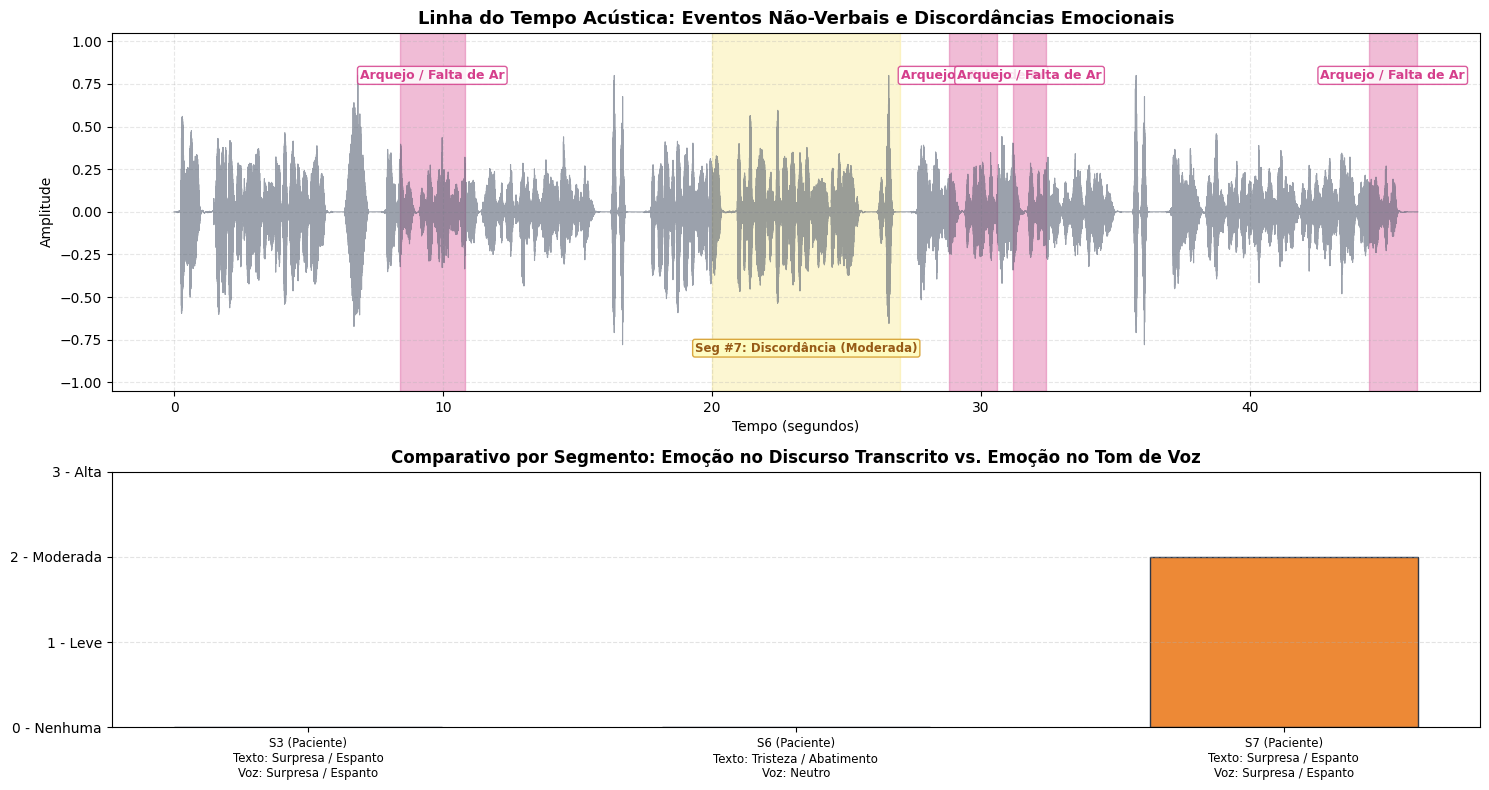

In [ ]:
def plot_multimodal_clinical_timeline(
    audio_path: Path, df_full: pd.DataFrame, df_events: pd.DataFrame
) -> None:
    y, sr = librosa.load(str(audio_path), sr=SAMPLE_RATE, mono=True)
    time_axis = np.linspace(0, len(y) / sr, num=len(y))

    fig, axes = plt.subplots(2, 1, figsize=(15, 8), gridspec_kw={"height_ratios": [1.4, 1.0]})
    plt.subplots_rule = "tight"

    # Painel 1: Forma de onda + Eventos não-verbais + Segmentos com discordância
    ax1 = axes[0]
    ax1.plot(time_axis, y, color="#4A5568", alpha=0.55, linewidth=0.8, label="Sinal de Áudio")

    event_colors = {
        "Tosse": "#E53E3E",
        "Limpeza de Garganta (Pigarro)": "#DD6B20",
        "Espirro": "#805AD5",
        "Suspiro": "#3182CE",
        "Arquejo / Falta de Ar": "#D53F8C",
    }

    for _, ev in df_events.iterrows():
        ev_name = ev["evento_clinico"]
        c = event_colors.get(ev_name, "#E53E3E")
        ax1.axvspan(ev["inicio_s"], ev["fim_s"], color=c, alpha=0.35)
        ax1.text(
            (ev["inicio_s"] + ev["fim_s"]) / 2,
            0.78,
            ev_name.split(" (")[0],
            color=c,
            fontsize=9,
            fontweight="bold",
            ha="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=c, alpha=0.85),
        )

    for _, seg in df_full.iterrows():
        if seg.get("ha_discordancia", False):
            ax1.axvspan(seg["inicio_s"], seg["fim_s"], color="#F6E05E", alpha=0.28)
            ax1.text(
                (seg["inicio_s"] + seg["fim_s"]) / 2,
                -0.82,
                f"Seg #{seg['segment_id']}: Discordância ({seg['nivel_discordancia']})",
                color="#975A16",
                fontsize=8.5,
                fontweight="bold",
                ha="center",
                bbox=dict(boxstyle="round,pad=0.2", fc="#FEFCBF", ec="#D69E2E", alpha=0.9),
            )

    ax1.set_title(
        "Linha do Tempo Acústica: Eventos Não-Verbais e Discordâncias Emocionais",
        fontsize=13,
        fontweight="bold",
    )
    ax1.set_xlabel("Tempo (segundos)")
    ax1.set_ylabel("Amplitude")
    ax1.set_ylim(-1.05, 1.05)
    ax1.grid(True, linestyle="--", alpha=0.3)

    # Painel 2: Nível de discordância por segmento
    ax2 = axes[1]
    level_score_map = {"Nenhuma": 0, "Leve": 1, "Moderada": 2, "Alta": 3}
    level_color_map = {
        "Nenhuma": "#48BB78",
        "Leve": "#ECC94B",
        "Moderada": "#ED8936",
        "Alta": "#E53E3E",
    }

    scores = [level_score_map.get(lvl, 0) for lvl in df_full["nivel_discordancia"]]
    colors = [level_color_map.get(lvl, "#A0AEC0") for lvl in df_full["nivel_discordancia"]]
    labels = [
        f"S{row['segment_id']} ({row['interlocutor']})\nTexto: {row['emocao_discurso_texto']}\nVoz: {row['emocao_voz_primaria']}"
        for _, row in df_full.iterrows()
    ]

    bars = ax2.bar(range(len(df_full)), scores, color=colors, edgecolor="#2D3748", width=0.55)
    ax2.set_xticks(range(len(df_full)))
    ax2.set_xticklabels(labels, fontsize=8.5)
    ax2.set_yticks([0, 1, 2, 3])
    ax2.set_yticklabels(["0 - Nenhuma", "1 - Leve", "2 - Moderada", "3 - Alta"])
    ax2.set_title(
        "Comparativo por Segmento: Emoção no Discurso Transcrito vs. Emoção no Tom de Voz",
        fontsize=12,
        fontweight="bold",
    )
    ax2.grid(axis="y", linestyle="--", alpha=0.35)

    plt.tight_layout()
    plt.savefig("linha_do_tempo_clinica.png", dpi=150)
    plt.show()


plot_multimodal_clinical_timeline(AUDIO_PATH, df_completo, df_non_verbal)

## 9. Módulo 6: Geração do Relatório de Discordâncias Emocionais e Eventos Não-Verbais
Por fim, geramos um relatório clínico estruturado destacando:
- **Resumo Executivo da Consulta** e **Estado Emocional Real do Paciente**;
- **Tabela de Eventos Acústicos Não-Verbais** (Tosse, Espirro, Limpeza de Garganta e afins);
- **Mapeamento Completo de Discordâncias entre Discurso Transcrito e Tom de Voz**;
- **Detalhamento Clínico das Discordâncias Identificadas**;
- **Recomendações Clínicas ao Médico**.

O relatório é exibido formatado no notebook e salvo automaticamente em `relatorio_discordancias_clinicas.md`.

In [ ]:
def generate_clinical_discordance_report(
    analysis: ClinicalConsultationAnalysis,
    df_full: pd.DataFrame,
    df_events: pd.DataFrame,
    output_md_path: Path = Path("relatorio_discordancias_clinicas.md"),
) -> str:
    """Formata e salva o relatório completo de discordâncias emocionais e eventos não-verbais."""
    total_segs = len(df_full)
    discordant_df = df_full[df_full["ha_discordancia"] == True]
    num_discordant = len(discordant_df)

    lines = [
        "# 📋 Relatório Clínico: Análise de Eventos Não-Verbais e Discordâncias Emocionais (Voz vs. Discurso)",
        "",
        "## 1. Resumo Geral da Consulta",
        f"{analysis.resumo_geral_consulta}",
        "",
        "## 2. Estado Emocional do Paciente (Voz vs. Palavras)",
        f"{analysis.padrao_emocional_paciente}",
        "",
        "## 3. Sons Não-Verbais Medicamente Relevantes Detectados",
        f"{analysis.avaliacao_eventos_nao_verbais}",
        "",
    ]

    if df_events.empty:
        lines.append(
            "_Nenhum evento não-verbal relevante detectado acima do limiar configurado._\n"
        )
    else:
        lines.append(
            "| Início (s) | Fim (s) | Evento Clínico Detectado | Confiança Acústica | Energia RMS |"
        )
        lines.append("| :---: | :---: | :--- | :---: | :---: |")
        for _, ev in df_events.iterrows():
            lines.append(
                f"| {ev['inicio_s']:.2f}s | {ev['fim_s']:.2f}s | **{ev['evento_clinico']}** | "
                f"{ev['confianca'] * 100:.1f}% | {ev['energia_rms']:.4f} |"
            )
        lines.append("")

    lines.extend(
        [
            "## 4. Comparativo Geral: Discurso Transcrito (Whisper + OpenAI) vs. Tom de Voz (SER Local)",
            f"- **Total de segmentos de fala analisados:** {total_segs}",
            f"- **Segmentos com discordância emocional detectada:** {num_discordant} ({(num_discordant / max(1, total_segs)) * 100:.1f}%)",
            "",
            "| Seg # | Tempo | Interlocutor | Transcrição (Whisper) | Emoção no Texto (OpenAI) | Emoção no Tom de Voz (Local) | Sons Não-Verbais Próximos | Discordância |",
            "| :---: | :---: | :---: | :--- | :--- | :--- | :--- | :---: |",
        ]
    )

    for _, row in df_full.iterrows():
        ev_str = (
            ", ".join(row["eventos_nao_verbais_proximos"])
            if row["eventos_nao_verbais_proximos"]
            else "—"
        )
        disc_badge = (
            f"⚠️ **{row['nivel_discordancia']}**" if row["ha_discordancia"] else "✅ Nenhuma"
        )
        lines.append(
            f"| {row['segment_id']} | {row['inicio_s']:.1f}s–{row['fim_s']:.1f}s | {row['interlocutor']} | "
            f'"{row["transcricao"]}" | {row["emocao_discurso_texto"]} | '
            f"{row['emocao_voz_primaria']} ({row['confianca_voz_primaria'] * 100:.0f}%) / {row['emocao_voz_secundaria']} | "
            f"{ev_str} | {disc_badge} |"
        )

    lines.extend(
        [
            "",
            "## 5. Detalhamento Clínico das Discordâncias Identificadas",
        ]
    )

    if discordant_df.empty:
        lines.append(
            "_Não foram identificadas discordâncias significativas entre o discurso verbal e o tom de voz._\n"
        )
    else:
        for _, row in discordant_df.iterrows():
            ev_str = (
                ", ".join(row["eventos_nao_verbais_proximos"])
                if row["eventos_nao_verbais_proximos"]
                else "Nenhum no entorno imediato"
            )
            lines.extend(
                [
                    f"### 🔍 Segmento #{row['segment_id']} ({row['inicio_s']:.1f}s a {row['fim_s']:.1f}s) — Interlocutor: {row['interlocutor']}",
                    f'- **Fala Transcrita:** *"{row["transcricao"]}"*',
                    f"- **Emoção Transmitida no Texto:** `{row['emocao_discurso_texto']}`",
                    f"- **Emoção Reconhecida no Tom de Voz:** `{row['emocao_voz_primaria']}` (confiança: {row['confianca_voz_primaria'] * 100:.1f}%) | Secundária: `{row['emocao_voz_secundaria']}`",
                    f"- **Métricas Prosódicas:** Pitch médio = `{row['pitch_medio_hz']} Hz` (desvio = `{row['pitch_std_hz']} Hz`), Energia RMS = `{row['energia_rms']}`",
                    f"- **Eventos Não-Verbais Associados:** {ev_str}",
                    f"- **Nível de Discordância:** **{row['nivel_discordancia']}**",
                    f"- **Parecer Clínico:** {row['explicacao_clinica']}",
                    "",
                ]
            )

    lines.extend(
        [
            "## 6. Recomendações Clínicas ao Médico",
        ]
    )
    for idx, rec in enumerate(analysis.recomendacoes_ao_medico, 1):
        lines.append(f"{idx}. {rec}")

    report_md = "\n".join(lines)
    output_md_path.write_text(report_md, encoding="utf-8")
    df_full.to_csv("analise_segmentos_clinicos.csv", index=False, encoding="utf-8-sig")
    print(f"Relatório salvo em: {output_md_path.resolve()}")
    return report_md


relatorio_markdown = generate_clinical_discordance_report(
    clinical_analysis, df_completo, df_non_verbal
)
display(Markdown(relatorio_markdown))

Relatório salvo em: /content/relatorio_discordancias_clinicas.md


# 📋 Relatório Clínico: Análise de Eventos Não-Verbais e Discordâncias Emocionais (Voz vs. Discurso)

## 1. Resumo Geral da Consulta
A consulta apresenta um paciente que demonstra sinais de desconforto respiratório, evidenciado por arquejos frequentes. O discurso do paciente oscila entre expressões de surpresa e um estado neutro, mas também revela uma tonalidade de tristeza em um dos segmentos. A presença de eventos não-verbais, como arquejos, sugere um estado de angústia ou dificuldade respiratória, contradizendo a aparente neutralidade ou surpresa nas falas.

## 2. Estado Emocional do Paciente (Voz vs. Palavras)
O paciente parece estar em um estado de confusão emocional, alternando entre surpresa e tristeza, enquanto apresenta sinais físicos de desconforto respiratório. A presença de arquejos sugere que, apesar de algumas expressões verbais neutras ou de surpresa, o paciente pode estar enfrentando um nível de estresse ou ansiedade.

## 3. Sons Não-Verbais Medicamente Relevantes Detectados
Os arquejos detectados indicam uma possível dificuldade respiratória ou ansiedade. Esses eventos não-verbais são significativos e devem ser considerados na avaliação do estado emocional e físico do paciente, pois podem sinalizar um desconforto que não é verbalizado diretamente.

| Início (s) | Fim (s) | Evento Clínico Detectado | Confiança Acústica | Energia RMS |
| :---: | :---: | :--- | :---: | :---: |
| 8.40s | 10.80s | **Arquejo / Falta de Ar** | 35.5% | 0.0682 |
| 28.80s | 30.60s | **Arquejo / Falta de Ar** | 16.3% | 0.0692 |
| 31.20s | 32.40s | **Arquejo / Falta de Ar** | 16.3% | 0.0594 |
| 44.40s | 46.20s | **Arquejo / Falta de Ar** | 34.7% | 0.0515 |

## 4. Comparativo Geral: Discurso Transcrito (Whisper + OpenAI) vs. Tom de Voz (SER Local)
- **Total de segmentos de fala analisados:** 3
- **Segmentos com discordância emocional detectada:** 1 (33.3%)

| Seg # | Tempo | Interlocutor | Transcrição (Whisper) | Emoção no Texto (OpenAI) | Emoção no Tom de Voz (Local) | Sons Não-Verbais Próximos | Discordância |
| :---: | :---: | :---: | :--- | :--- | :--- | :--- | :---: |
| 3 | 7.0s–9.0s | Paciente | "Ah, Tamsa!" | Surpresa / Espanto | Surpresa / Espanto (13%) / Neutro | Arquejo / Falta de Ar | ✅ Nenhuma |
| 6 | 17.0s–20.0s | Paciente | "Pasebiku Vose Tosu Agora." | Tristeza / Abatimento | Neutro (13%) / Tristeza / Abatimento | — | ✅ Nenhuma |
| 7 | 20.0s–27.0s | Paciente | "Esa Tosu Yo Kansaso No Pato Continuum Fortes Annoyte." | Surpresa / Espanto | Surpresa / Espanto (13%) / Neutro | Arquejo / Falta de Ar | ⚠️ **Moderada** |

## 5. Detalhamento Clínico das Discordâncias Identificadas
### 🔍 Segmento #7 (20.0s a 27.0s) — Interlocutor: Paciente
- **Fala Transcrita:** *"Esa Tosu Yo Kansaso No Pato Continuum Fortes Annoyte."*
- **Emoção Transmitida no Texto:** `Surpresa / Espanto`
- **Emoção Reconhecida no Tom de Voz:** `Surpresa / Espanto` (confiança: 13.1%) | Secundária: `Neutro`
- **Métricas Prosódicas:** Pitch médio = `211.2 Hz` (desvio = `45.8 Hz`), Energia RMS = `0.0877`
- **Eventos Não-Verbais Associados:** Arquejo / Falta de Ar
- **Nível de Discordância:** **Moderada**
- **Parecer Clínico:** Embora o paciente expresse surpresa, a presença de arquejos indica desconforto respiratório, sugerindo uma discordância entre a emoção verbalizada e o estado físico.

## 6. Recomendações Clínicas ao Médico
1. Investigar a causa dos arquejos e desconforto respiratório do paciente.
2. Promover um ambiente de escuta ativa para que o paciente possa expressar suas preocupações.
3. Considerar a possibilidade de ansiedade ou estresse como fatores contribuintes para os sintomas físicos.
4. Realizar uma avaliação mais aprofundada do estado emocional do paciente, especialmente em relação à tristeza expressa.